# ESPRI 质子能量回归：左右臂独立 MLP

**功能**：分别读取 `InputRootFiles/Processed_Left.root/tree` 和 `InputRootFiles/Processed_right.root/tree`，以
`[ENaI, RDCX, RDCY]` 预测顶点质子动能 `ETrue`，保存两个独立模型及诊断结果。

**方法**：uproot/awkward → NumPy float128 → 每臂独立随机 80%/20% 划分 → 仅训练集归一化 →
CPU float128 的 `3→128→128→128→1` Tanh MLP。Adam 初始学习率 `1e-4`，SmoothL1Loss(beta=0.01)，batch 256，
余弦退火，固定 2000 轮；逐轮以 `eval()` 和 `no_grad()` 重算完整训练集与测试集损失。
不使用验证集、早停或最优测试损失选模，始终保存最后一轮权重。

**注意事项**：能量为 MeV、坐标为 mm；输入仅为 ENaI、RDCX、RDCY，不读取或筛选 NaIBarID。
ROOT 输入位于 `InputRootFiles/`；修改后须重新训练左右臂的三输入模型。
`ENaI` 为所选臂最大 NaI 棒的展宽读出能量；
RDCX/Y 保持实验读出约定。`ETrue` 是初始质子的发射动能，网络直接输出该量，不再次加 ENaI。
预处理已施加 55–70°、同臂塑闪–NaI 符合、唯一有效 RDC 命中及近似 NaI 阻停条件；这里不重跑宏。
这是包含探测器响应和随机能损的条件回归，测试残差不等同于材料本征能损涨落。
每行对应一个筛选后的事件；当前树没有原始 EventID，因此保存的 SourceEntry 仅指预处理树行号。
20% 数据用于测试监控；若据其结果调整参数，该集合就参与了模型选择。
模型训练和图表由你手动运行；训练输出固定保存到 `EspriEnergy_output/`，运行会覆盖其中同名结果。
能量残差柱状图显示 −10～10 MeV，bin 宽 0.2 MeV；误差指标仍使用全部有效事件。

单元格顺序和显式代码风格参照用户指定的 `../EnergyLoss/EnergyLoss.ipynb`。
训练损失作用于标准化标签；MSE、RMSE 等作为反归一化到 MeV 后的评价指标。

## 1. 导入、固定随机数及输入配置
网络结构在模型单元格显式定义；训练轮数、优化器和损失函数参数在训练单元格定义。
依赖 `torch`、`uproot`、`awkward`、`numpy`、`matplotlib`，使用 CPU float128。
实现参照 `nndl-practice/pytorch/chap4前馈神经网络/前馈神经网络-上.ipynb` 的 Sequential 模式，
以及用户指定的 `EnergyLoss/EnergyLoss.ipynb` 的单元格划分和 SmoothL1 设置。

In [1]:
# 功能：分别训练左右臂的顶点质子动能回归模型并保存完整模型、预处理与诊断。
# 方法：三输入 Tanh MLP（ENaI、RDCX、RDCY），CPU/float64，独立 80/20，SmoothL1Loss、Adam+余弦退火，固定轮数。
# 注意事项：ROOT 输入位于 InputRootFiles；只用训练集拟合归一化，测试集只监控；能量 MeV、坐标 mm；须重新训练三输入模型。

from pathlib import Path
import json
import random
import hashlib
import numpy as np
import awkward as ak
import uproot
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
device = torch.device("cpu")
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})
print(f"PyTorch {torch.__version__}; device={device}; dtype={DTYPE}")

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
INPUT_FILES = {
    "Left": INPUT_ROOT_DIR / "Processed_Left.root",
    "Right": INPUT_ROOT_DIR / "Processed_right.root",
}
TREE_NAME = "tree"
FEATURE_NAMES = ["ENaI", "RDCX", "RDCY"]
FEATURE_UNITS = ["MeV", "mm", "mm"]
TARGET_NAME = "ETrue"
INVALID_VALUE = -999.0
ARM_SEEDS = {"Left": 42, "Right": 43}
TRAIN_FRACTION = 0.80
RESIDUAL_HIST_MIN_MEV = -10.0
RESIDUAL_HIST_MAX_MEV = 10.0
RESIDUAL_HIST_BIN_WIDTH_MEV = 0.2

OUTPUT_DIR = PROJECT_DIR / "EspriEnergy_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("输出目录：", OUTPUT_DIR)
print("预测 Notebook 的 MODEL_DIR 请填写此目录。")


PyTorch 2.5.1; device=cpu; dtype=torch.float64
输出目录： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output
预测 Notebook 的 MODEL_DIR 请填写此目录。


## 2. 读取 ROOT 并检查事件对齐
左右臂分别读取指定三个标量输入和标签 ETrue，每行保持同一 ROOT entry 的对应关系。
明确排除输入非有限值、ENaI≤0、输入等于 -999 或标签非有限/≤0 的行，逐臂报告排除数。
SourceEntry 是预处理树行号；每个原始事件最多一行，不额外施加物理筛选。

In [2]:
def read_features(path, tree_name, feature_names, target_name="ETrue"):
    """读取标量预处理树；保留全部行，标签可以不存在。"""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"ROOT 文件不存在：{path}")
    with uproot.open(path) as root_file:
        tree = root_file[tree_name]
        missing = [name for name in feature_names if name not in tree.keys()]
        if missing:
            raise ValueError(f"{path.name}/{tree_name} 缺少输入分支：{missing}")
        has_target = target_name in tree.keys()
        names = list(feature_names) + ([target_name] if has_target else [])
        arrays = tree.arrays(names, library="ak", how=dict)
        columns = [np.asarray(ak.to_numpy(arrays[name]), dtype=np.float64) for name in names]
        if any(column.ndim != 1 for column in columns):
            raise ValueError("需要每个事件一行的标量分支，不接受未预处理的多命中数组。")
        if len({len(column) for column in columns}) != 1:
            raise ValueError("输入与标签的行数不一致。")
        X = np.column_stack(columns[:len(feature_names)]).astype(np.float64)
        y = columns[-1].reshape(-1, 1) if has_target else None
    return X, y


def valid_features(X):
    # 不新增角度或坐标接受度门；预处理已经负责物理筛选。
    finite = np.isfinite(X).all(axis=1)
    return finite & (X[:, 0] > 0.0) & (X != INVALID_VALUE).all(axis=1)

datasets = {}
for arm, path in INPUT_FILES.items():
    X_all, y_all = read_features(path, TREE_NAME, FEATURE_NAMES, TARGET_NAME)
    if y_all is None:
        raise ValueError(f"{arm} 训练文件必须包含 {TARGET_NAME}。")
    input_ok = valid_features(X_all)
    target_ok = np.isfinite(y_all[:, 0]) & (y_all[:, 0] > 0.0)
    keep = input_ok & target_ok
    source_rows = np.arange(len(X_all), dtype=np.int64)[keep]
    X, y = X_all[keep], y_all[keep]
    if len(X) < 5:
        raise ValueError(f"{arm} 有效事件数不足以划分训练/测试集。")
    datasets[arm] = {
        "X": X, "y": y, "source_rows": source_rows, "input_path": path.resolve(),
        "input_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "original_entries": len(X_all), "rejected_entries": int((~keep).sum()),
    }
    print(f"{arm}: 原始 {len(X_all)}，输入无效 {(~input_ok).sum()}，标签无效 {(~target_ok).sum()}，"
          f"合计排除 {(~keep).sum()}，保留 {len(X)}")
    print("  feature minima:", dict(zip(FEATURE_NAMES, X.min(axis=0))))
    print("  feature maxima:", dict(zip(FEATURE_NAMES, X.max(axis=0))))
    print(f"  ETrue range: {y.min():.6g}–{y.max():.6g} MeV")


Left: 原始 24006，输入无效 0，标签无效 0，合计排除 0，保留 24006
  feature minima: {'ENaI': np.float64(0.2078763012513422), 'RDCX': np.float64(112.06673818573219), 'RDCY': np.float64(18.522068663701816)}
  feature maxima: {'ENaI': np.float64(125.91301180247619), 'RDCX': np.float64(399.3273479131202), 'RDCY': np.float64(427.92354384297494)}
  ETrue range: 18.5195–179.996 MeV
Right: 原始 24149，输入无效 0，标签无效 0，合计排除 0，保留 24149
  feature minima: {'ENaI': np.float64(0.15498845045936438), 'RDCX': np.float64(48.45831757412378), 'RDCY': np.float64(24.51877856102081)}
  feature maxima: {'ENaI': np.float64(137.54049436590878), 'RDCX': np.float64(331.00826472962615), 'RDCY': np.float64(424.37408075696976)}
  ETrue range: 22.7589–179.996 MeV


## 3. 划分与训练集归一化
Left 使用 seed 42，Right 使用 seed 43，分别固定随机打乱后划分 80%/20%。
每臂的均值、标准差只从自己的训练集计算；保持已有划分算法，以便比较损失函数的影响。
常量输入列按训练集极差识别，均值取实际常量、缩放量设为 1。

In [3]:
splits = {}
for arm, data in datasets.items():
    rng = np.random.default_rng(ARM_SEEDS[arm])
    order = rng.permutation(len(data["X"]))
    n_train = int(TRAIN_FRACTION * len(order))
    train_idx, test_idx = order[:n_train], order[n_train:]
    X_train, X_test = data["X"][train_idx], data["X"][test_idx]
    y_train, y_test = data["y"][train_idx], data["y"][test_idx]

    x_mean = X_train.mean(axis=0)
    x_std_raw = X_train.std(axis=0)
    constant_features = np.ptp(X_train, axis=0) == 0.0
    x_mean[constant_features] = X_train[0, constant_features]
    x_std = np.where(constant_features | (x_std_raw == 0.0), 1.0, x_std_raw)
    y_mean = y_train.mean(axis=0)
    y_std = y_train.std(axis=0)
    if np.ptp(y_train) == 0.0:
        raise ValueError(f"{arm} 训练标签是常量，无法学习能损映射。")
    y_std = np.where(y_std == 0.0, 1.0, y_std)

    X_train_n = (X_train - x_mean) / x_std
    X_test_n = (X_test - x_mean) / x_std
    y_train_n = (y_train - y_mean) / y_std
    y_test_n = (y_test - y_mean) / y_std
    splits[arm] = {
        "train_idx": train_idx, "test_idx": test_idx,
        "X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
        "X_train_n": X_train_n, "X_test_n": X_test_n,
        "y_train_n": y_train_n, "y_test_n": y_test_n,
        "x_mean": x_mean, "x_std": x_std, "y_mean": y_mean, "y_std": y_std,
        "constant_features": constant_features,
    }
    print(f"{arm}: train={len(train_idx)}, test/monitor={len(test_idx)}")
    print("  constant features:", [name for name, flag in zip(FEATURE_NAMES, constant_features) if flag])
    print("  training target mean/std (MeV):", y_mean, y_std)


Left: train=19204, test/monitor=4802
  constant features: []
  training target mean/std (MeV): [94.2230315] [36.67308054]
Right: train=19319, test/monitor=4830
  constant features: []
  training target mean/std (MeV): [93.9900532] [36.51625419]


## 4. 张量与 MLP
显式定义 `3→128→128→128→1`，三个隐藏层使用 Tanh，输出层为线性层。
左右臂使用相同结构、各自独立的模型参数和训练集归一化。所有张量与模型均使用 CPU float64。

In [ ]:
def to_tensor(array):
    return torch.from_numpy(np.ascontiguousarray(array, dtype=np.float64)).to(
        device=device, dtype=DTYPE
    )


for arm in ("Left", "Right"):
    split = splits[arm]
    X_train_n, y_train_n = split["X_train_n"], split["y_train_n"]
    X_test_n, y_test_n = split["X_test_n"], split["y_test_n"]
    X_train_t, y_train_t = to_tensor(X_train_n), to_tensor(y_train_n)
    X_test_t, y_test_t = to_tensor(X_test_n), to_tensor(y_test_n)
    split.update({
        "X_train_t": X_train_t, "y_train_t": y_train_t,
        "X_test_t": X_test_t, "y_test_t": y_test_t,
    })


# 显式定义 3 -> 64 -> 64 -> 64 -> 1，三个隐藏层使用 Tanh。
def build_model():
    return nn.Sequential(
        nn.Linear(3, 128), nn.Tanh(),
        nn.Linear(128, 128), nn.Tanh(),
        nn.Linear(128, 128), nn.Tanh(),
        nn.Linear(128, 1),
    )


print(build_model())


Sequential(
  (0): Linear(in_features=3, out_features=128, bias=True)
  (1): Tanh()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): Tanh()
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): Tanh()
  (6): Linear(in_features=128, out_features=1, bias=True)
)


## 5. 固定轮数训练与完整集合损失监控
训练参数和循环在本单元格直接给出。重新执行时，每臂从各自固定种子初始化全新模型、
优化器、余弦学习率调度器和 DataLoader 随机生成器。
使用 `nn.SmoothL1Loss(beta=0.01)`；beta 作用于标准化标签残差，不是 0.01 MeV。
固定训练 2000 轮，不早停、不按测试损失选权重。
每轮更新结束后，在同一模型状态下用 eval()/no_grad() 重算完整训练集和测试集损失。

In [5]:
# 训练参数在本单元格显式定义，便于直接修改。
LEARNING_RATE = 1e-4
MINIMUM_LEARNING_RATE = 1e-6
epoch_count = 2000
COSINE_EPOCHS = epoch_count
BATCH_SIZE = 256
WEIGHT_DECAY = 0.0
SMOOTH_L1_BETA = 0.01  # 作用于标准化标签残差，不是 0.01 MeV。
LOG_EVERY = 100

models, histories = {}, {}
for arm in ("Left", "Right"):
    split = splits[arm]
    X_train_t, y_train_t = split["X_train_t"], split["y_train_t"]
    X_test_t, y_test_t = split["X_test_t"], split["y_test_t"]
    seed = ARM_SEEDS[arm]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = build_model().to(device=device, dtype=DTYPE)
    criterion = nn.SmoothL1Loss(beta=SMOOTH_L1_BETA)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=COSINE_EPOCHS, eta_min=MINIMUM_LEARNING_RATE
    )
    loader_generator = torch.Generator(device="cpu").manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator,
        num_workers=0, drop_last=False,
    )

    train_loss_history, test_loss_history, learning_rate_history = [], [], []
    print(f"\nTraining {arm}: CPU float64, SmoothL1Loss(beta={SMOOTH_L1_BETA})")
    print(model)
    for epoch in range(1, epoch_count + 1):
        learning_rate_history.append(float(optimizer.param_groups[0]["lr"]))
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss).item():
                raise RuntimeError(f"{arm} epoch {epoch} 训练损失出现 NaN/Inf。")
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_loss = criterion(model(X_train_t), y_train_t).item()
            test_loss = criterion(model(X_test_t), y_test_t).item()
        if not np.isfinite(train_loss) or not np.isfinite(test_loss):
            raise RuntimeError(f"{arm} epoch {epoch} 完整集合损失出现 NaN/Inf。")
        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        scheduler.step()
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == epoch_count:
            print(f"{arm} epoch {epoch:4d}/{epoch_count}: train={train_loss:.6g}, "
                  f"test/monitor={test_loss:.6g}, lr={learning_rate_history[-1]:.4g}")

    model.eval()
    models[arm] = model
    histories[arm] = {
        "train_loss_history": train_loss_history,
        "test_loss_history": test_loss_history,
        "learning_rate": learning_rate_history,
    }
    print(f"Finished {arm}: {epoch_count} epochs; using final model weights.")



Training Left: CPU float64, SmoothL1Loss(beta=0.01)
Sequential(
  (0): Linear(in_features=3, out_features=128, bias=True)
  (1): Tanh()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): Tanh()
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): Tanh()
  (6): Linear(in_features=128, out_features=1, bias=True)
)
Left epoch    1/2000: train=0.223001, test/monitor=0.224048, lr=0.0001
Left epoch  100/2000: train=0.0185786, test/monitor=0.0188552, lr=9.94e-05
Left epoch  200/2000: train=0.0155996, test/monitor=0.0162109, lr=9.76e-05
Left epoch  300/2000: train=0.0149355, test/monitor=0.0156865, lr=9.464e-05
Left epoch  400/2000: train=0.0193754, test/monitor=0.0199319, lr=9.059e-05
Left epoch  500/2000: train=0.013916, test/monitor=0.0147692, lr=8.556e-05
Left epoch  600/2000: train=0.0143933, test/monitor=0.0152036, lr=7.966e-05
Left epoch  700/2000: train=0.013105, test/monitor=0.0139193, lr=7.304e-05
Left epoch  800/2000: train=0.0130133, test/monitor=0.01

## 6. 单独绘制损失曲线
两条曲线都是每轮结束后同一模型状态下的完整集合 SmoothL1 loss，纵轴采用对数。
左右臂独立显示；20% 数据仅用于监控。

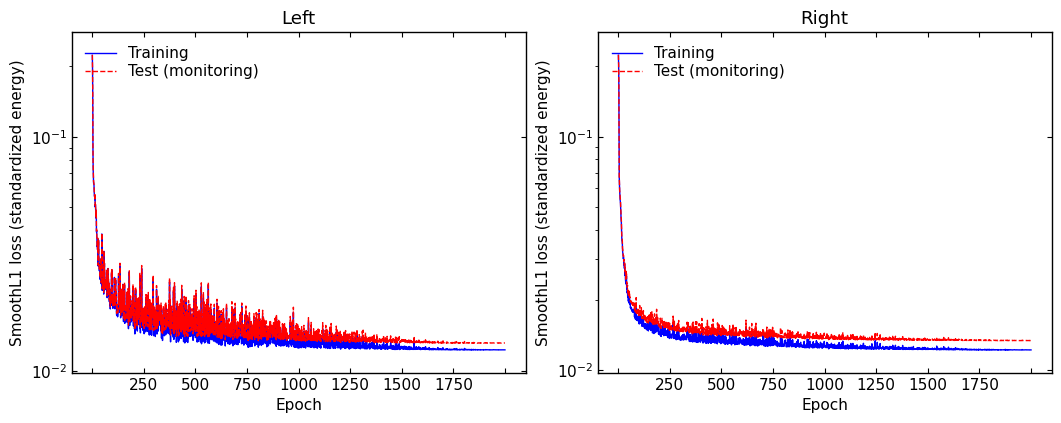

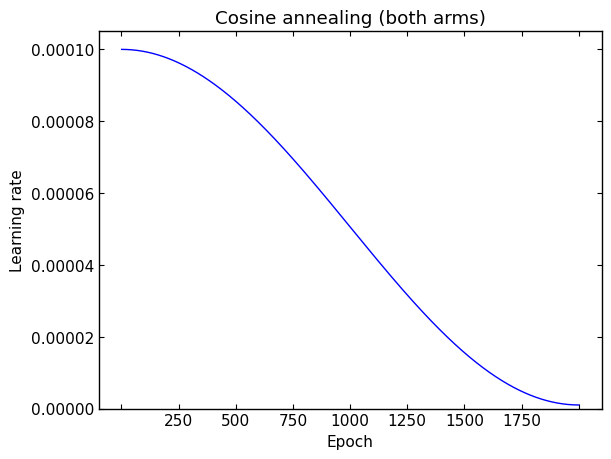

In [6]:
def finish_figure(fig, axes, path):
    """统一绘图区比例，隐藏横轴首尾可见刻度文字，并紧凑导出。"""
    axes = np.asarray(axes, dtype=object).reshape(-1)
    for ax in axes:
        ax.set_box_aspect(3.0 / 4.0)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
    fig.canvas.draw()
    for ax in axes:
        low, high = sorted(ax.get_xlim())
        labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                  if low <= tick.get_loc() <= high and tick.label1.get_visible()]
        if len(labels) > 1:
            labels[0].set_visible(False)
            labels[-1].set_visible(False)
    fig.savefig(path, bbox_inches="tight", pad_inches=0.06)
    plt.show()
    plt.close(fig)

epochs = np.arange(1, epoch_count + 1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
for ax, arm in zip(axes, ("Left", "Right")):
    ax.plot(epochs, histories[arm]["train_loss_history"], color="blue", linewidth=1, label="Training")
    ax.plot(epochs, histories[arm]["test_loss_history"], color="red", linestyle="--", linewidth=1, label="Test (monitoring)")
    ax.set(yscale="log", xlabel="Epoch", ylabel="SmoothL1 loss (standardized energy)", title=arm)
    loss_values = np.concatenate((histories[arm]["train_loss_history"], histories[arm]["test_loss_history"]))
    positive_losses = loss_values[loss_values > 0.0]
    if len(positive_losses):
        ax.set_ylim(0.8 * positive_losses.min(), 1.25 * positive_losses.max())
    ax.legend(frameon=False, loc="upper left", labelspacing=0.2)
finish_figure(fig, axes, OUTPUT_DIR / "LossCurves.pdf")

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
# 两臂调度参数一致，显示每轮优化器实际使用的共同学习率。
ax.plot(epochs, histories["Left"]["learning_rate"], color="blue", linewidth=1)
ax.set(xlabel="Epoch", ylabel="Learning rate", title="Cosine annealing (both arms)")
ax.set_ylim(0.0, 1.05 * LEARNING_RATE)
finish_figure(fig, [ax], OUTPUT_DIR / "LearningRate.pdf")


## 7. 固定轮数后的预测和残差（MeV）
残差定义为预测减真值；反归一化后分别报告训练与内部测试的 MSE、RMSE、MAE、R²、
Bias、样本残差标准差和中心68%半宽。评价 MSE 与训练 SmoothL1 是不同的量。
柱状图显示 [-10,10] MeV，bin 宽0.2 MeV；统计指标仍使用全部有效事件。
SourceEntry 是预处理树零起始行号。

Left train {
  "n": 19204,
  "mse_MeV2": 3.6072940829480147,
  "rmse_MeV": 1.89928778307765,
  "mae_MeV": 0.6036324055573379,
  "r2": 0.9973178271327373,
  "bias_MeV": -0.09621871524593247,
  "residual_std_MeV": 1.8968983658115763,
  "residual_q16_MeV": -0.5646392687540532,
  "residual_median_MeV": 0.01578459858812664,
  "residual_q84_MeV": 0.5579543644024784,
  "central68_half_width_MeV": 0.5612968165782658
}
Left test {
  "n": 4802,
  "mse_MeV2": 4.599198850827616,
  "rmse_MeV": 2.144574281956122,
  "mae_MeV": 0.6343669674531938,
  "r2": 0.9965810984102624,
  "bias_MeV": -0.11957037823209776,
  "residual_std_MeV": 2.141461361872055,
  "residual_q16_MeV": -0.5870427200692734,
  "residual_median_MeV": 0.00642501618631286,
  "residual_q84_MeV": 0.5648927933256553,
  "central68_half_width_MeV": 0.5759677566974644
}
Right train {
  "n": 19319,
  "mse_MeV2": 3.75727827450587,
  "rmse_MeV": 1.938370004541411,
  "mae_MeV": 0.5958726932567825,
  "r2": 0.9971822599937564,
  "bias_MeV": -0.1226

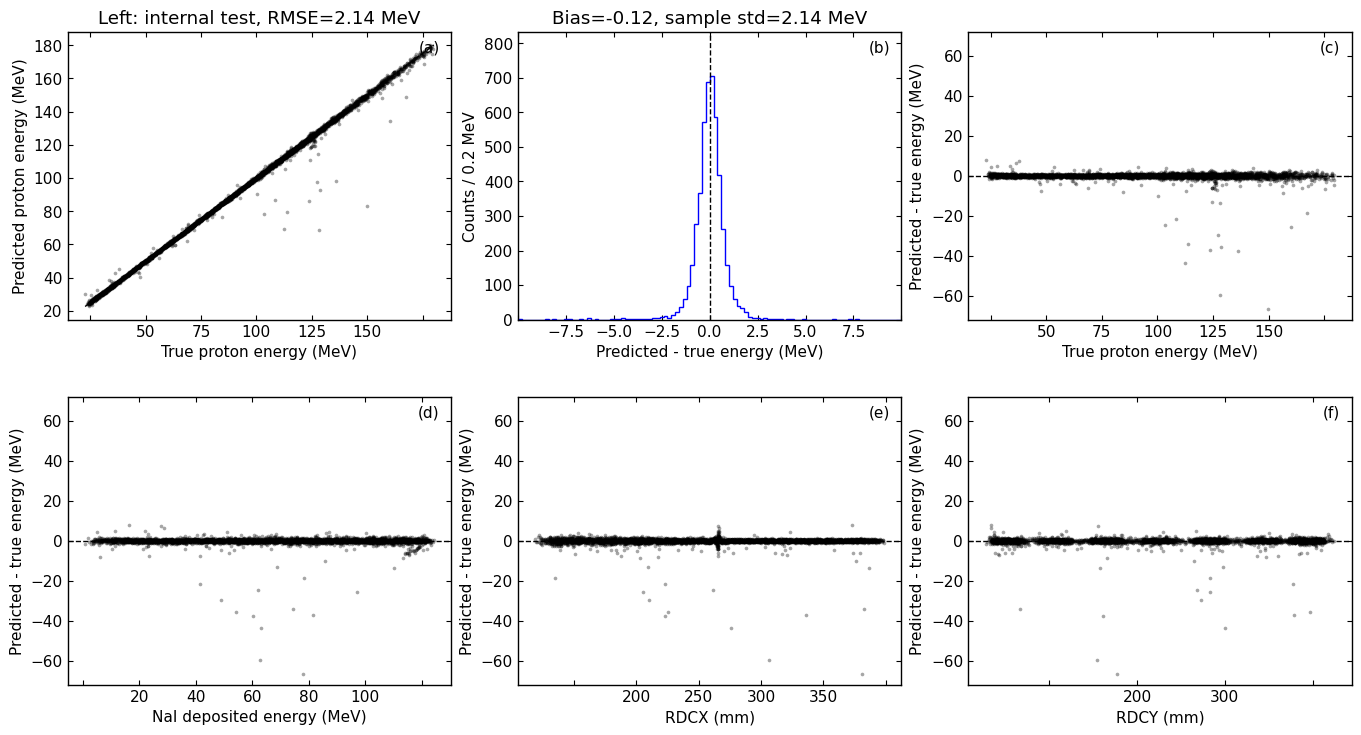

Right internal test: residual histogram below range=22, above range=0; metrics use all 4830 events


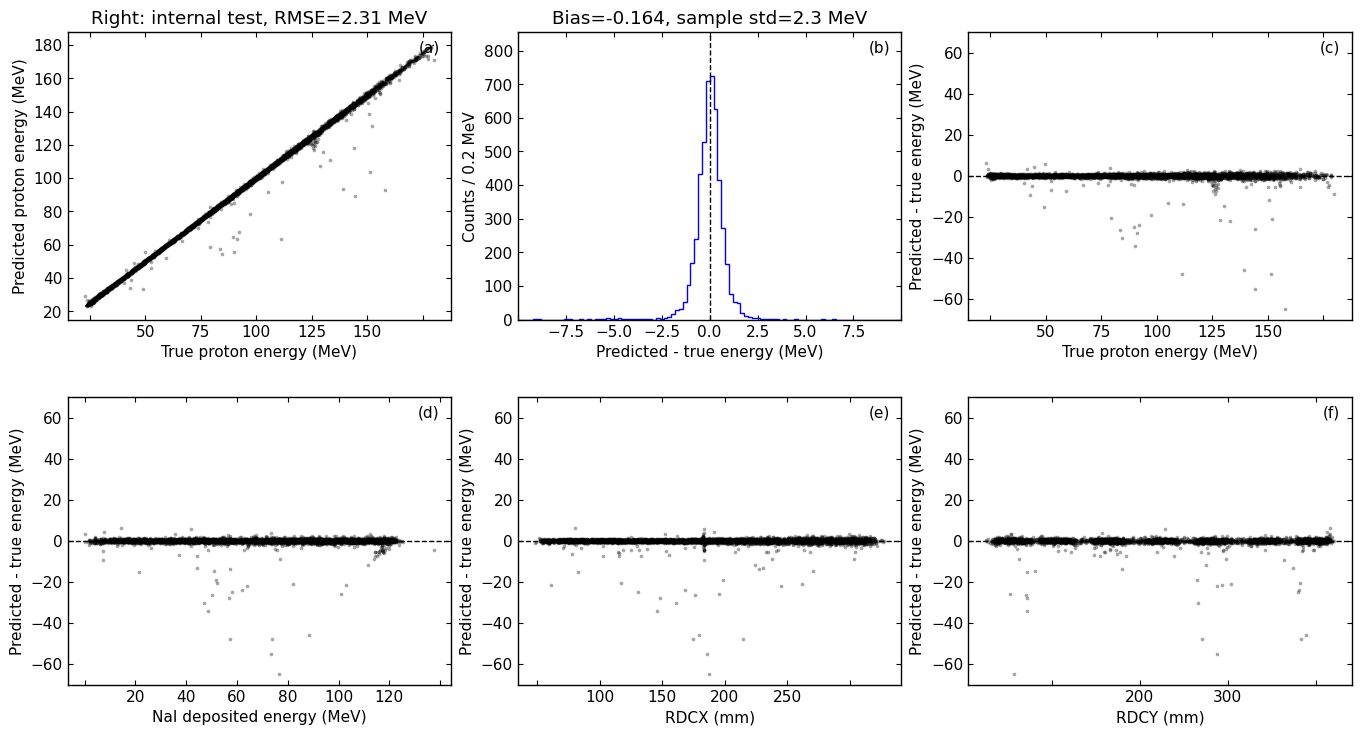

所有训练产物： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output


In [7]:
def regression_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    residual = prediction - truth
    if len(residual) == 0:
        raise ValueError("没有可用于计算误差的有效真值。")
    mse = float(np.mean(residual**2))
    total = float(np.sum((truth - truth.mean())**2))
    q16, q50, q84 = np.quantile(residual, [0.16, 0.50, 0.84])
    return {
        "n": int(len(residual)), "mse_MeV2": mse,
        "rmse_MeV": float(np.sqrt(mse)), "mae_MeV": float(np.mean(np.abs(residual))),
        "r2": float(1.0 - np.sum(residual**2) / total) if total > 0.0 else None,
        "bias_MeV": float(residual.mean()),
        "residual_std_MeV": float(residual.std(ddof=1)) if len(residual) > 1 else 0.0,
        "residual_q16_MeV": float(q16), "residual_median_MeV": float(q50),
        "residual_q84_MeV": float(q84), "central68_half_width_MeV": float((q84 - q16) / 2.0),
    }

def plot_diagnostics(arm, X, truth, prediction, path, sample_label):
    """所有宽度均为样本统计量，不进行高斯拟合。"""
    truth = np.asarray(truth).reshape(-1)
    prediction = np.asarray(prediction).reshape(-1)
    residual = prediction - truth
    metrics = regression_metrics(truth, prediction)
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.3), layout="constrained")
    ax = axes[0, 0]
    ax.scatter(truth, prediction, s=7, color="black", alpha=0.35, linewidths=0)
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(bounds, bounds, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="True proton energy (MeV)", ylabel="Predicted proton energy (MeV)")
    ax.set_title(f"{arm}: {sample_label}, RMSE={metrics['rmse_MeV']:.3g} MeV")
    ax = axes[0, 1]
    # 固定 100 个箱；只改变显示，不用这个窗口筛选误差指标。
    bin_count = int(round((RESIDUAL_HIST_MAX_MEV - RESIDUAL_HIST_MIN_MEV) / RESIDUAL_HIST_BIN_WIDTH_MEV))
    histogram_edges = np.linspace(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV, bin_count + 1)
    counts, edges, _ = ax.hist(residual, bins=histogram_edges, histtype="step", color="blue", linewidth=1)
    ax.set_xlim(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV)
    print(f"{arm} {sample_label}: residual histogram below range={(residual < RESIDUAL_HIST_MIN_MEV).sum()}, "
          f"above range={(residual > RESIDUAL_HIST_MAX_MEV).sum()}; metrics use all {len(residual)} events")
    ax.set_ylim(0.0, max(1.0, 1.18 * counts.max()))
    ax.set(xlabel="Predicted - true energy (MeV)", ylabel=f"Counts / {edges[1] - edges[0]:.3g} MeV")
    ax.set_title(f"Bias={metrics['bias_MeV']:.3g}, sample std={metrics['residual_std_MeV']:.3g} MeV")
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
    xs = [truth, X[:, 0], X[:, 1], X[:, 2]]
    labels = ["True proton energy (MeV)", "NaI deposited energy (MeV)", "RDCX (mm)", "RDCY (mm)"]
    residual_limit = max(1e-6, 1.08 * np.max(np.abs(residual)))
    for ax, values, label in zip([axes[0, 2], *axes[1]], xs, labels):
        ax.scatter(values, residual, s=7, color="black", alpha=0.35, linewidths=0)
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set(xlabel=label, ylabel="Predicted - true energy (MeV)")
        ax.set_ylim(-residual_limit, residual_limit)
    for index, ax in enumerate(axes.flat):
        ax.text(0.97, 0.97, f"({chr(97 + index)})", transform=ax.transAxes, ha="right", va="top")
    finish_figure(fig, axes, path)

all_metrics, test_results = {}, {}
for arm in ("Left", "Right"):
    model, split = models[arm], splits[arm]
    all_metrics[arm] = {}
    model.eval()
    for subset in ("train", "test"):
        with torch.no_grad():
            prediction_n = model(split[f"X_{subset}_t"]).cpu().numpy()
        prediction = prediction_n * split["y_std"] + split["y_mean"]
        truth = split[f"y_{subset}"]
        metrics = regression_metrics(truth, prediction)
        all_metrics[arm][subset] = metrics
        print(arm, subset, json.dumps(metrics, ensure_ascii=False, indent=2))
        if subset == "test":
            source_rows = datasets[arm]["source_rows"][split["test_idx"]]
            result = np.column_stack((source_rows, split["X_test"], truth, prediction, prediction - truth))
            np.savetxt(OUTPUT_DIR / f"InternalTest_{arm}.csv", result, delimiter=",",
                       header="SourceEntry,ENaI_MeV,RDCX_mm,RDCY_mm,ETrue_MeV,EPred_MeV,Residual_MeV",
                       comments="", fmt=["%d"] + ["%.17g"] * 6)
            test_results[arm] = {"X": split["X_test"], "truth": truth, "prediction": prediction}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(all_metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

for arm, result in test_results.items():
    plot_diagnostics(arm, result["X"], result["truth"], result["prediction"],
                     OUTPUT_DIR / f"InternalTestDiagnostics_{arm}.pdf", "internal test")
print("所有训练产物：", OUTPUT_DIR)


## 8. 保存训练得到的模型
保存固定轮数最后一轮的两份完整 nn.Sequential 模型、各自的训练集归一化、输入顺序与单位、
划分行号、原文件 SHA256、SmoothL1 的 beta、结构和训练历史。
固定输出目录为 EspriEnergy_output，运行保存单元格会覆盖其中同名结果。
预测 Notebook 直接加载保存的完整模型，不需要重新定义网络。

In [8]:
# 从实际模型提取层宽，网络只在“张量与 MLP”单元格定义。
linear_layers = [layer for layer in models["Left"] if isinstance(layer, nn.Linear)]
layer_sizes = [linear_layers[0].in_features] + [layer.out_features for layer in linear_layers]
configuration = {
    "feature_names": FEATURE_NAMES, "feature_units": FEATURE_UNITS, "target_name": TARGET_NAME,
    "target_definition": "Proton kinetic energy at emission vertex (MeV)",
    "layer_sizes": layer_sizes, "activation": "Tanh", "dtype": "float64", "device": "cpu",
    "epochs": epoch_count, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "minimum_learning_rate": MINIMUM_LEARNING_RATE, "cosine_epochs": COSINE_EPOCHS,
    "scheduler": "CosineAnnealingLR", "optimizer": "Adam", "loss": "SmoothL1Loss on standardized ETrue", "smooth_l1_beta": SMOOTH_L1_BETA,
    "train_fraction": TRAIN_FRACTION, "arm_seeds": ARM_SEEDS, "weight_decay": WEIGHT_DECAY,
    "checkpoint_rule": "final_epoch", "torch_version": str(torch.__version__),
}
for arm in ("Left", "Right"):
    split, data = splits[arm], datasets[arm]
    saved = {
        "model": models[arm].cpu().eval(), "arm": arm,
        "feature_names": FEATURE_NAMES.copy(), "feature_units": FEATURE_UNITS.copy(),
        "target_name": TARGET_NAME, "target_unit": "MeV",
        "target_definition": configuration["target_definition"],
        "x_mean": split["x_mean"], "x_std": split["x_std"],
        "y_mean": split["y_mean"], "y_std": split["y_std"],
        "train_feature_min": split["X_train"].min(axis=0),
        "train_feature_max": split["X_train"].max(axis=0),
        "source_rows_train": data["source_rows"][split["train_idx"]],
        "source_rows_test": data["source_rows"][split["test_idx"]],
        "input_path": str(data["input_path"]), "input_sha256": data["input_sha256"],
        "tree_name": TREE_NAME, "original_entries": data["original_entries"],
        "rejected_entries": data["rejected_entries"], "epoch": epoch_count,
        "configuration": configuration, "history": histories[arm],
    }
    checkpoint_path = OUTPUT_DIR / f"EspriEnergy_{arm}.pt"
    torch.save(saved, checkpoint_path)
    np.savez(OUTPUT_DIR / f"History_{arm}.npz", **histories[arm])
    print("Saved:", checkpoint_path)
(OUTPUT_DIR / "configuration.json").write_text(json.dumps(configuration, ensure_ascii=False, indent=2), encoding="utf-8")
print("预测配置 MODEL_DIR =", repr(str(OUTPUT_DIR)))


Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output/EspriEnergy_Left.pt
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output/EspriEnergy_Right.pt
预测配置 MODEL_DIR = '/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/EspriEnergy_output'


## 9. 下一步

`PreProcess.C` 依次处理 `InputRootFiles/Espri.root` 和 `InputRootFiles/Espri_Evaluation.root`。
四份预处理树均输出到 `InputRootFiles/`；独立样本为 `Processed_Left_Eval.root`、`Processed_Right_Eval.root`，已配置到预测 Notebook。
`EspriEnergyEvaluation.ipynb` 默认读取固定模型目录；预测沿用保存的输入顺序、单位和训练集归一化。
新文件可含 ETrue 进行独立误差评估，也可只有三项输入进行预测。